# He weight initialization ----> ReLU

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/ipartzix/ML-Dataset/ushape.csv")

In [3]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


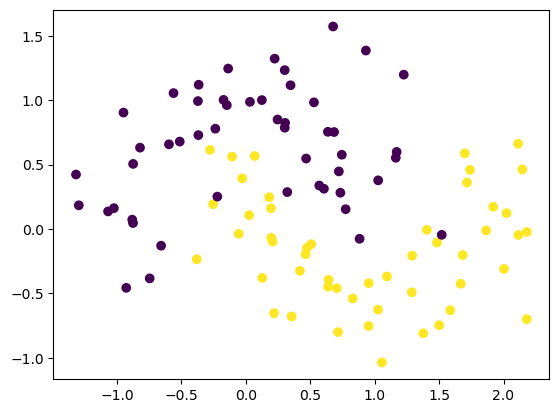

In [4]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [5]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [6]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [7]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/home/ipartzix/miniconda3/envs/MLE/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.get_weights()

[array([[ 1.1213163 , -1.4817985 , -0.8537315 , -0.20172359,  0.15102942,
         -0.32092676, -1.4959532 , -1.129668  ,  0.72433925, -1.0451896 ],
        [ 0.8091172 ,  1.6469092 , -0.04806599, -0.6141104 ,  0.6946343 ,
         -0.6461937 ,  0.1066788 ,  1.398139  , -0.14032468, -1.0613542 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.95626336, -0.27714598, -0.11147323, -0.3907431 ,  0.2083063 ,
          0.974298  , -0.22757266,  0.08497795, -0.53151053, -0.1217595 ],
        [ 0.9424369 , -0.39583883, -0.3508965 ,  0.7736571 , -0.8959016 ,
         -0.3663175 , -0.1950001 ,  0.19668154,  0.45903838,  0.6465119 ],
        [-0.19765452, -0.737905  , -0.76230925,  0.06517581,  0.58181596,
         -0.5378524 ,  0.24899557, -0.32143083,  0.96735257, -0.44307384],
        [-0.19488676, -0.39086756,  0.67246616,  0.12311471, -0.56480646,
         -0.08179756, -0.27525806, -0.39266542,  0.534353  ,  0.40525246],
        [-0.31062

In [9]:
initial_weights = model.get_weights()

In [10]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [11]:
model.set_weights(initial_weights)

In [12]:
model.get_weights()

[array([[-0.5517653 ,  0.48776323,  0.1770075 ,  0.47170377,  1.359013  ,
          0.7040082 , -0.6092818 ,  0.07305163, -0.9467903 ,  0.97894794],
        [-0.11203859, -1.0086282 , -0.1464302 , -0.6901924 ,  0.39930627,
         -0.53805035,  0.30337533,  0.62532634, -0.8380601 ,  0.4886715 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.2602467 ,  0.31962478,  0.08560299, -0.0503093 ,  0.3260611 ,
         -0.50854015, -0.5258827 ,  0.2939587 , -0.2581924 , -0.35429946],
        [-0.17388469,  0.10321674,  0.157209  , -0.58472574, -0.37803024,
          0.06459296, -0.15181881, -0.05523684, -0.36866796, -0.05739682],
        [ 0.04569089,  0.30681646,  0.10950276,  0.42793053,  0.24372883,
          0.3425746 , -0.4294241 ,  0.61443996, -0.7408656 ,  0.19055568],
        [-0.38207036,  0.224473  , -0.02776879,  0.26720583, -0.06464287,
         -0.4791303 ,  0.1201338 , -0.33410335, -0.3316058 ,  0.4717119 ],
        [ 0.01694

In [13]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [14]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step - accuracy: 0.7125 - loss: 0.6312 - val_accuracy: 0.8500 - val_loss: 0.6204
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.7750 - loss: 0.6253 - val_accuracy: 0.8500 - val_loss: 0.6139
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7875 - loss: 0.6196 - val_accuracy: 0.8500 - val_loss: 0.6075
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8000 - loss: 0.6141 - val_accuracy: 0.8500 - val_loss: 0.6009
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8125 - loss: 0.6083 - val_accuracy: 0.8500 - val_loss: 0.5943
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8250 - loss: 0.6030 - val_accuracy: 0.8500 - val_loss: 0.5873
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.8250 - loss: 0.5965 - val_accuracy: 0.8500 - val_loss: 0.5802
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8250 - loss: 0.5908 - val_accuracy: 0.8500 - val_loss

In [15]:
model.get_weights()

[array([[-0.40800565,  0.58547777,  0.29112035,  0.53630817,  1.5014367 ,
          0.7562036 , -0.8373552 ,  0.08529056, -1.204903  ,  1.1199675 ],
        [-0.14766985, -1.0654105 , -0.22796994, -0.9040173 ,  0.39560488,
         -0.7460894 ,  0.46782336,  0.8014885 , -0.6214784 ,  0.3884143 ]],
       dtype=float32),
 array([-0.10165527,  0.04419871, -0.10698962,  0.09952695,  0.14007945,
         0.03220093, -0.04061836,  0.09353853,  0.04381974, -0.08242551],
       dtype=float32),
 array([[ 0.2602467 ,  0.31962478,  0.09521975, -0.0503093 ,  0.46428654,
         -0.27910468, -0.5670607 ,  0.24532057, -0.0527906 , -0.45851293],
        [-0.17388469,  0.07533115,  0.32422146, -0.58472574, -0.24131252,
          0.04233833,  0.00780811, -0.04435428, -0.59752727,  0.10637846],
        [ 0.04569089,  0.28054684,  0.2710056 ,  0.42793053,  0.3481864 ,
          0.28085312, -0.27424368,  0.61443996, -0.9798936 ,  0.34944388],
        [-0.38207036,  0.19592206,  0.1417356 ,  0.26720583, 

<Axes: >

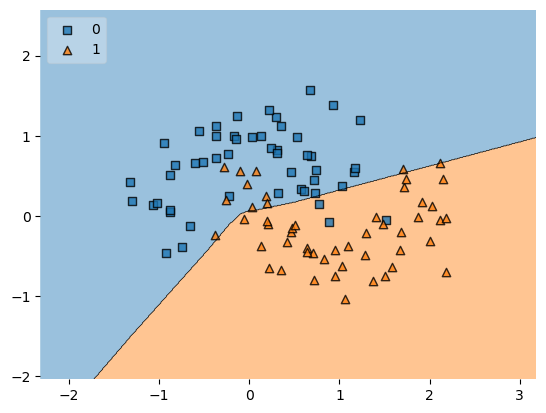

In [16]:
import numpy as np
from mlxtend.plotting import plot_decision_regions


class KerasClassifierWrapper:

    def __init__(self, model):
        self.model = model

    def predict(self, X):
        y_pred = self.model.predict(X, verbose=0)
        return (y_pred > 0.5).astype(int).ravel()


clf = KerasClassifierWrapper(model)

plot_decision_regions(
    X=np.array(X), y=np.array(y).astype(int).ravel(), clf=clf, legend=2
)

In [17]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.03074362426366906)

In [18]:
(np.random.randn(10,10)*0.01).max()

np.float64(0.025985809245358427)